# Transfermarkt-derived uploads — dated valuations and profile audit

These CSVs were supplied by the user with claimed origin salimt/football-datasets; their exact repository commit was not verified. Original bytes are copied unchanged into data/raw/transfermarkt. Amounts are reported market assessments; EUR is assumed, not explicit in the source. No valuation model is trained.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
while not (ROOT/'src/config.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run within the project')
    ROOT = ROOT.parent
import sys
sys.path.insert(0,str(ROOT))
from src.data.provenance import sha256
manifest=json.loads((ROOT/'data/processed/manifest.json').read_text(encoding='utf-8'))
def table(name):
    info=manifest['outputs'][name]
    path=ROOT/info['parquet_path']
    assert sha256(path)==info['parquet_sha256'], 'Prepared table checksum changed'
    return pd.read_parquet(path)


In [2]:
profiles=table('transfermarkt_profiles');values=table('transfermarkt_values')
print('Profiles:',len(profiles),'Dated valuation records:',len(values))
print('Duplicate player/date keys:',int(values.duplicated(['source_player_id','valuation_date']).sum()))
print('Recorded zero values:',int(values.reported_zero_value.sum()))
print('Valuation date range:',values.valuation_date.min(),values.valuation_date.max())

Profiles: 92671 Dated valuation records: 901429


Duplicate player/date keys: 0
Recorded zero values: 48009
Valuation date range: 2003-12-14 00:00:00 2025-09-11 00:00:00


In [3]:
pd.DataFrame({'missing':profiles.isna().sum(),'missing_pct':profiles.isna().mean()*100,'dtype':profiles.dtypes.astype(str)}).sort_values('missing_pct',ascending=False)

,missing,missing_pct,dtype
foot,23488,25.345577,object
height_cm,18871,20.363436,float64
birth_year,1006,1.085561,Int64
date_of_birth,1006,1.085561,datetime64[ns]
date_of_birth_raw,1006,1.085561,object
player_raw,520,0.561125,object
height_raw_cm,4,0.004316,float64
main_position,2,0.002158,object
position_source,2,0.002158,object
source_player_id,0,0.000000,string


## Cleaning and units

Source profile IDs and dated valuation keys are validated. Height zero sentinels are retained in the raw field and become missing clean centimetres. Profile name suffix IDs are removed for display, never used as a universal key. ISO valuation dates are parsed; negative/invalid amounts fail validation. Zero does not automatically mean a free player. Current position/club fields do not establish historical membership or role.

Latest positive values: 33590 Latest zero/unknown: 35851


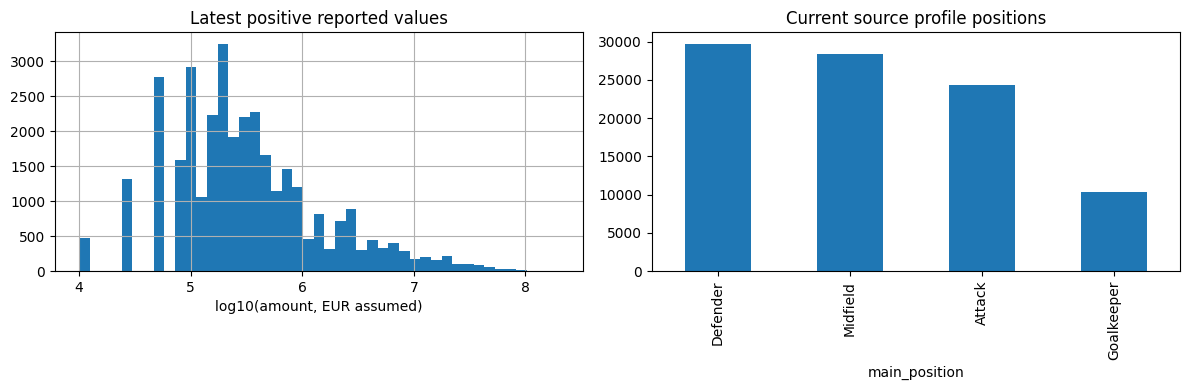

In [4]:
values.market_value_eur.describe(percentiles=[.5,.9,.95,.99]).to_frame()
latest=values.sort_values('valuation_date').drop_duplicates('source_player_id',keep='last')
positive=latest[latest.market_value_eur.gt(0)].copy()
print('Latest positive values:',len(positive),'Latest zero/unknown:',len(latest)-len(positive))
import numpy as np
fig,axes=plt.subplots(1,2,figsize=(12,4))
np.log10(positive.market_value_eur).hist(bins=45,ax=axes[0]);axes[0].set(title='Latest positive reported values',xlabel='log10(amount, EUR assumed)')
profiles.main_position.value_counts().head(12).plot.bar(ax=axes[1]);axes[1].set_title('Current source profile positions');plt.tight_layout();plt.show()

In [5]:
yearly=values.assign(year=values.valuation_date.dt.year).groupby('year').agg(records=('source_player_id','size'),players=('source_player_id','nunique'),median_amount=('market_value_eur','median'))
yearly

,records,players,median_amount
year,,,
2003,1,1,900000.0
2004,8062,6734,250000.0
2005,6188,4399,500000.0
2006,5798,4391,500000.0
2007,10895,7353,600000.0
2008,17484,10589,500000.0
2009,21425,12710,500000.0
2010,25231,15192,400000.0
2011,27883,16026,350000.0


In [6]:
combined=positive.merge(profiles[['source_player_id','height_cm','birth_year','main_position']],on='source_player_id',how='left',validate='one_to_one')
combined[['market_value_eur','height_cm','birth_year']].corr()
combined.groupby('main_position').market_value_eur.agg(['count','median'])

,count,median
main_position,,
Attack,9422,300000.0
Defender,10972,250000.0
Goalkeeper,3310,175000.0
Midfield,9886,250000.0


## Interpretation and integration boundary

Reported values are strongly right-skewed; log plotting changes the display, not the stored amounts. Position/value grouping uses current profiles and cannot be interpreted as historical valuations by role. Global uploaded profiles do not establish historical league coverage. Cross-source links use upstream IDs supported by normalized name/birth year, but remain provisional. In Streamlit values filter candidates after ranking, with dates and uncertainty labels. Original publication timestamps and explicit currency are unknown, so these records do not prove historical affordability and never enter recommendation fitting. Expert or primary-source verification remains pending.